<a href="https://colab.research.google.com/github/NurSyahira02/Google-Colab/blob/main/DSML_Clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Clustering Analysis


In [ ]:
import pandas as pd
import numpy as np


df = pd.read_csv('https://raw.githubusercontent.com/fakhitah3/DSML/refs/heads/main/Final_Output.csv')
df

,WaterbodyName,Years,SampleDate,Alkalinity-total (as CaCO3),Ammonia-Total (as N),BOD - 5 days (Total),Chloride,Conductivity @25°C,Dissolved Oxygen,ortho-Phosphate (as P) - unspecified,pH,Temperature,Total Hardness (as CaCO3),True Colour,WQI Value,Label
0,LEE (CORK)_020,2008,Jan,8.0,0.069,1.3,13.2,69.0,54.10,0.005,6.89,8.9,10.8,33.0,74.281978,Fair
1,LEE (CORK)_021,2008,Jan,9.0,0.068,1.3,14.8,77.0,54.00,0.005,6.89,9.7,11.7,28.0,74.755756,Fair
2,LEE (CORK)_022,2008,Mar,15.0,0.033,1.4,16.0,106.0,53.90,0.021,7.18,6.6,17.0,22.0,72.037731,Fair
3,LEE (CORK)_023,2008,Mar,13.0,0.040,1.2,15.7,159.0,53.35,0.005,6.88,6.4,15.0,22.0,75.465689,Fair
4,LEE (CORK)_024,2008,Mar,12.0,0.039,1.1,16.0,144.0,53.40,0.021,7.23,6.3,16.3,24.0,71.975552,Fair
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7785,LEE (CORK)_7805,2022,Jun,44.0,1.500,2.5,19.2,172.0,56.55,0.056,7.40,15.7,44.0,23.0,63.915606,Marginal
7786,LEE (CORK)_7806,2022,Sep,31.0,0.140,2.8,21.2,160.0,53.95,0.015,7.10,14.9,45.0,27.0,74.858858,Fair
7787,LEE (CORK)_7807,2022,Nov,22.0,0.190,1.5,16.2,118.0,54.30,0.021,6.90,12.3,34.0,58.0,69.188960,Fair
7788,LEE (CORK)_7808,2023,Mar,36.0,0.210,1.6,17.4,151.0,52.40,0.059,7.20,7.1,44.0,20.0,70.234195,Fair


In [ ]:
#drop unnecesary column
import numpy as np


df = df.drop(['WaterbodyName', 'Label'], axis=1)
df


,Years,SampleDate,Alkalinity-total (as CaCO3),Ammonia-Total (as N),BOD - 5 days (Total),Chloride,Conductivity @25°C,Dissolved Oxygen,ortho-Phosphate (as P) - unspecified,pH,Temperature,Total Hardness (as CaCO3),True Colour,WQI Value
0,2008,Jan,8.0,0.069,1.3,13.2,69.0,54.10,0.005,6.89,8.9,10.8,33.0,74.281978
1,2008,Jan,9.0,0.068,1.3,14.8,77.0,54.00,0.005,6.89,9.7,11.7,28.0,74.755756
2,2008,Mar,15.0,0.033,1.4,16.0,106.0,53.90,0.021,7.18,6.6,17.0,22.0,72.037731
3,2008,Mar,13.0,0.040,1.2,15.7,159.0,53.35,0.005,6.88,6.4,15.0,22.0,75.465689
4,2008,Mar,12.0,0.039,1.1,16.0,144.0,53.40,0.021,7.23,6.3,16.3,24.0,71.975552
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7785,2022,Jun,44.0,1.500,2.5,19.2,172.0,56.55,0.056,7.40,15.7,44.0,23.0,63.915606
7786,2022,Sep,31.0,0.140,2.8,21.2,160.0,53.95,0.015,7.10,14.9,45.0,27.0,74.858858
7787,2022,Nov,22.0,0.190,1.5,16.2,118.0,54.30,0.021,6.90,12.3,34.0,58.0,69.188960
7788,2023,Mar,36.0,0.210,1.6,17.4,151.0,52.40,0.059,7.20,7.1,44.0,20.0,70.234195


In [ ]:
# prompt: transform the SampleDate to numeric format using encoding

from sklearn.preprocessing import LabelEncoder

# Assuming 'SampleDate' is the column you want to transform
le = LabelEncoder()
df['SampleDate'] = le.fit_transform(df['SampleDate'])

df


,Years,SampleDate,Alkalinity-total (as CaCO3),Ammonia-Total (as N),BOD - 5 days (Total),Chloride,Conductivity @25°C,Dissolved Oxygen,ortho-Phosphate (as P) - unspecified,pH,Temperature,Total Hardness (as CaCO3),True Colour,WQI Value
0,2008,4,8.0,0.069,1.3,13.2,69.0,54.10,0.005,6.89,8.9,10.8,33.0,74.281978
1,2008,4,9.0,0.068,1.3,14.8,77.0,54.00,0.005,6.89,9.7,11.7,28.0,74.755756
2,2008,7,15.0,0.033,1.4,16.0,106.0,53.90,0.021,7.18,6.6,17.0,22.0,72.037731
3,2008,7,13.0,0.040,1.2,15.7,159.0,53.35,0.005,6.88,6.4,15.0,22.0,75.465689
4,2008,7,12.0,0.039,1.1,16.0,144.0,53.40,0.021,7.23,6.3,16.3,24.0,71.975552
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7785,2022,6,44.0,1.500,2.5,19.2,172.0,56.55,0.056,7.40,15.7,44.0,23.0,63.915606
7786,2022,11,31.0,0.140,2.8,21.2,160.0,53.95,0.015,7.10,14.9,45.0,27.0,74.858858
7787,2022,9,22.0,0.190,1.5,16.2,118.0,54.30,0.021,6.90,12.3,34.0,58.0,69.188960
7788,2023,7,36.0,0.210,1.6,17.4,151.0,52.40,0.059,7.20,7.1,44.0,20.0,70.234195


In [ ]:
# drop True Colour	WQI Value - unnecessary column

df = df.drop(['True Colour', 'WQI Value'], axis=1)
df


,Years,SampleDate,Alkalinity-total (as CaCO3),Ammonia-Total (as N),BOD - 5 days (Total),Chloride,Conductivity @25°C,Dissolved Oxygen,ortho-Phosphate (as P) - unspecified,pH,Temperature,Total Hardness (as CaCO3),cluster
0,2008,4,8.0,0.069,1.3,13.2,69.0,54.10,0.005,6.89,8.9,10.8,1
1,2008,4,9.0,0.068,1.3,14.8,77.0,54.00,0.005,6.89,9.7,11.7,1
2,2008,7,15.0,0.033,1.4,16.0,106.0,53.90,0.021,7.18,6.6,17.0,1
3,2008,7,13.0,0.040,1.2,15.7,159.0,53.35,0.005,6.88,6.4,15.0,1
4,2008,7,12.0,0.039,1.1,16.0,144.0,53.40,0.021,7.23,6.3,16.3,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
7785,2022,6,44.0,1.500,2.5,19.2,172.0,56.55,0.056,7.40,15.7,44.0,1
7786,2022,11,31.0,0.140,2.8,21.2,160.0,53.95,0.015,7.10,14.9,45.0,1
7787,2022,9,22.0,0.190,1.5,16.2,118.0,54.30,0.021,6.90,12.3,34.0,1
7788,2023,7,36.0,0.210,1.6,17.4,151.0,52.40,0.059,7.20,7.1,44.0,1


In [ ]:
# clustering analysis using k-means

from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# Assuming 'df' is your DataFrame with numerical features

# Scale the data
x = df.values
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

# Determine the optimal number of clusters (optional)
# You can use methods like the elbow method or silhouette score

# Apply KMeans clustering
kmeans = KMeans(n_clusters=3, random_state=42)  # Replace 3 with the desired number of clusters
kmeans.fit(x_scaled)

# Get the cluster labels for each data point
df['cluster'] = kmeans.labels_

# Analyze the clusters
# For example, you can calculate the mean values of features for each cluster
cluster_means = df.groupby('cluster').mean()

# Print the cluster means
cluster_means




,Years,SampleDate,Alkalinity-total (as CaCO3),Ammonia-Total (as N),BOD - 5 days (Total),Chloride,Conductivity @25°C,Dissolved Oxygen,ortho-Phosphate (as P) - unspecified,pH,Temperature,Total Hardness (as CaCO3)
cluster,,,,,,,,,,,,
0,2014.367016,5.859162,204.863613,0.082961,1.50022,22.260994,486.054927,67.361660,0.032997,7.884414,10.863974,237.519284
1,2014.530242,5.641129,65.698483,0.117303,1.52668,17.549981,219.684143,58.213438,0.038567,7.362566,10.581013,77.048392
2,2017.000000,4.000000,130.000000,0.027000,1.30000,1260.000000,4200.000000,54.900000,0.021000,7.500000,6.600000,574.000000


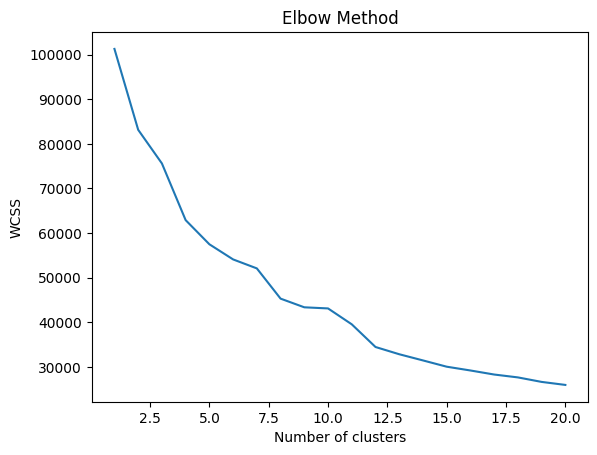

In [ ]:
# compute elbow method for optimal k value using wcss

wcss = []
for i in range(1, 21):
    kmeans = KMeans(n_clusters=i, random_state=42)
    kmeans.fit(x_scaled)
    wcss.append(kmeans.inertia_)

# Plot the Elbow Method graph
import matplotlib.pyplot as plt
plt.plot(range(1, 21), wcss)
plt.title('Elbow Method')
plt.xlabel('Number of clusters')
plt.ylabel('WCSS')
plt.show()


In [ ]:
# prompt: evaluate the cluster using sillhouette score

from sklearn.metrics import silhouette_score

# Assuming 'x_scaled' is your scaled data and 'kmeans' is your KMeans model
silhouette_avg = silhouette_score(x_scaled, kmeans.labels_)
print("The average silhouette_score is :", silhouette_avg)


The average silhouette_score is : 0.29590382589654013


Sillhoute Score between -1 to 1. Higher value is better

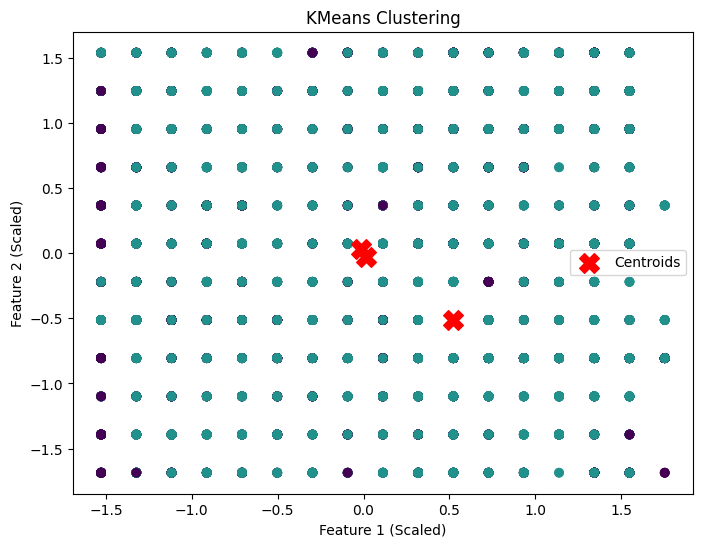

In [ ]:
# generate visualisation for the kmean cluster

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

# Visualize the clusters using a scatter plot (assuming you have 2 or 3 relevant features)
plt.figure(figsize=(8, 6))
plt.scatter(x_scaled[:, 0], x_scaled[:, 1], c=kmeans.labels_, cmap='viridis')  # Replace 0 and 1 with your feature indices
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], s=200, c='red', marker='X', label='Centroids')
plt.title('KMeans Clustering')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.legend()
plt.show()


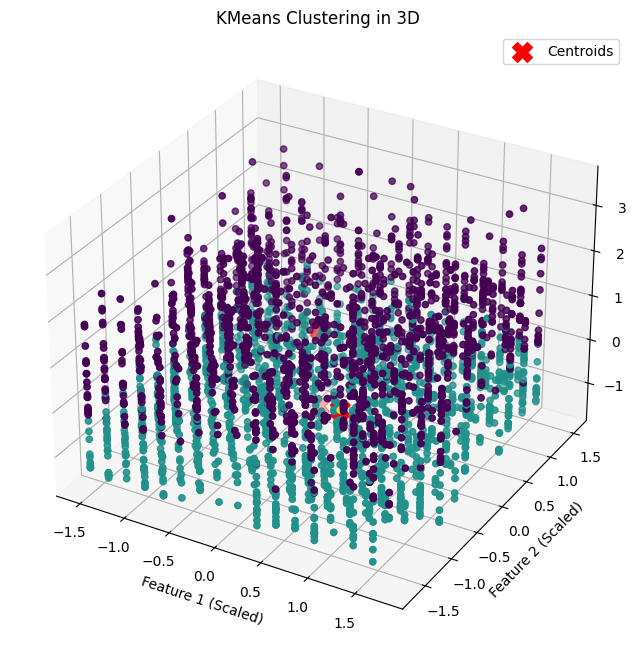

In [ ]:
# visualize the cluster in 3d format

import pandas as pd
import numpy as np
from sklearn.preprocessing import LabelEncoder
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
from sklearn.metrics import silhouette_score


# ... (Your existing code for data loading, preprocessing, and clustering) ...

# Assuming 'x_scaled' is your scaled data and 'kmeans' is your KMeans model

# Visualize the clusters in 3D (assuming you have at least 3 relevant features)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(x_scaled[:, 0], x_scaled[:, 1], x_scaled[:, 2], c=kmeans.labels_, cmap='viridis')  # Replace 0, 1, 2 with your feature indices
ax.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1], kmeans.cluster_centers_[:, 2], s=200, c='red', marker='X', label='Centroids')
ax.set_xlabel('Feature 1 (Scaled)')
ax.set_ylabel('Feature 2 (Scaled)')
ax.set_zlabel('Feature 3 (Scaled)')
ax.set_title('KMeans Clustering (3D)')
plt.legend()
plt.show()


In [ ]:
# interprete the cluster in detail by stating the criteria of each cluster

# Analyze the clusters in detail
cluster_means = df.groupby('cluster').mean()

print("Cluster Means:\n", cluster_means)


Cluster Means:
                Years  SampleDate  Alkalinity-total (as CaCO3)  \
cluster                                                         
0        2014.367016    5.859162                   204.863613   
1        2014.530242    5.641129                    65.698483   
2        2017.000000    4.000000                   130.000000   

         Ammonia-Total (as N)  BOD - 5 days (Total)     Chloride  \
cluster                                                            
0                    0.082961               1.50022    22.260994   
1                    0.117303               1.52668    17.549981   
2                    0.027000               1.30000  1260.000000   

         Conductivity @25°C  Dissolved Oxygen  \
cluster                                         
0                486.054927         67.361660   
1                219.684143         58.213438   
2               4200.000000         54.900000   

         ortho-Phosphate (as P) - unspecified        pH  Temperature  \

# Iris Dataset

In [ ]:
# load iris dataset

from sklearn.datasets import load_iris

iris = load_iris()
iris_df = pd.DataFrame(data=iris.data, columns=iris.feature_names)
iris_df['target'] = iris.target

iris_df


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [ ]:
iris_df = iris_df.drop(['target'], axis=1)
iris_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2
...,...,...,...,...
145,6.7,3.0,5.2,2.3
146,6.3,2.5,5.0,1.9
147,6.5,3.0,5.2,2.0
148,6.2,3.4,5.4,2.3


In [ ]:
# do k-mean clustering for iris_df and computer the sillhouette score

# Assuming 'iris_df' is your DataFrame with numerical features

# Scale the data
x = iris_df.values
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

# Determine the optimal number of clusters (optional)
# You can use methods like the elbow method or silhouette score

# Apply KMeans clustering
kmeans = KMeans(n_clusters=4, random_state=42)  # Replace 3 with the desired number of clusters
kmeans.fit(x_scaled)

# Get the cluster labels for each data point
iris_df['cluster'] = kmeans.labels_

# Analyze the clusters
# For example, you can calculate the mean values of features for each cluster
cluster_means = iris_df.groupby('cluster').mean()

# Assuming 'x_scaled' is your scaled data and 'kmeans' is your KMeans model
silhouette_avg = silhouette_score(x_scaled, kmeans.labels_)
print("The average silhouette_score is :", silhouette_avg)

# Sillhoute Score between -1 to 1. Higher value is better


The average silhouette_score is : 0.4457611293825252


k = 2, score = 0.52

k = 3, score = 0.53

k = 4, score = 0.44



# DBSCAN

In [ ]:
# compute dbscan clustering for df

from sklearn.cluster import DBSCAN

# Assuming 'x_scaled' is your scaled data

# Apply DBSCAN clustering
dbscan = DBSCAN(eps=0.5, min_samples=5)  # Adjust eps and min_samples as needed
dbscan.fit(x_scaled)

# Get the cluster labels for each data point
df['cluster_dbscan'] = dbscan.labels_

# Analyze the clusters
# For example, you can calculate the mean values of features for each cluster
cluster_means_dbscan = df.groupby('cluster_dbscan').mean()

# Print the cluster means
print("DBSCAN Cluster Means:\n", cluster_means_dbscan)


DBSCAN Cluster Means:
                       Years  SampleDate  Alkalinity-total (as CaCO3)  \
cluster_dbscan                                                         
-1              2014.454245    5.769739                   132.157512   
 0              2008.000000    4.000000                     8.500000   
 1              2008.000000    7.000000                    13.500000   
 2              2008.000000    6.000000                    17.000000   
 3              2008.000000    9.000000                    13.666667   
...                     ...         ...                          ...   
 153            2010.000000    2.000000                    37.000000   
 154            2016.333333    2.000000                    54.333333   
 155            2021.000000    3.000000                    58.000000   
 156            2020.000000    9.000000                    13.500000   
 157            2022.000000    9.000000                    17.666667   

                Ammonia-Total (as N)  BO

The average silhouette_score for DBSCAN is : -0.40837780942155055
Number of clusters found by DBSCAN: 158
Number of noise points found by DBSCAN: 6054


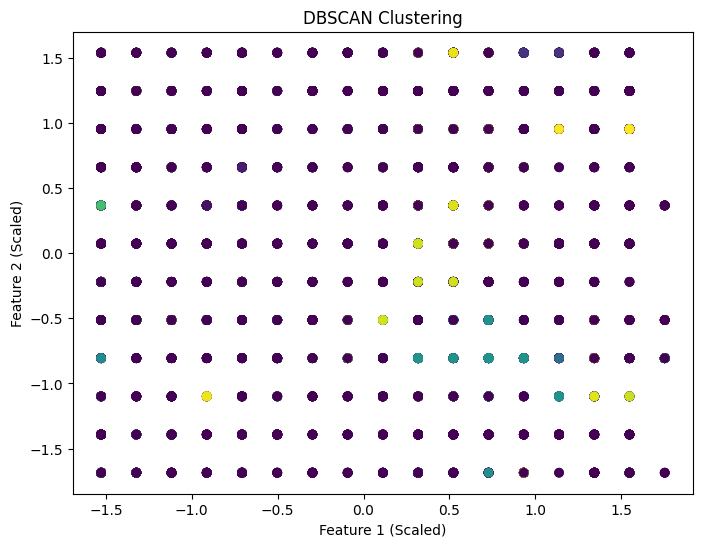

In [ ]:
# evaluate the dbscan cluster

# Assuming 'x_scaled' is your scaled data and 'dbscan' is your DBSCAN model

# Evaluate DBSCAN using silhouette score
silhouette_avg_dbscan = silhouette_score(x_scaled, dbscan.labels_)
print("The average silhouette_score for DBSCAN is :", silhouette_avg_dbscan)

# Analyze the number of clusters found by DBSCAN
n_clusters_dbscan = len(set(dbscan.labels_)) - (1 if -1 in dbscan.labels_ else 0)
print("Number of clusters found by DBSCAN:", n_clusters_dbscan)

# Analyze the number of noise points (labeled as -1)
n_noise_dbscan = list(dbscan.labels_).count(-1)
print("Number of noise points found by DBSCAN:", n_noise_dbscan)

# You can further analyze the clusters by examining the characteristics of data points
# within each cluster. For example, you can calculate the mean, median, or other
# descriptive statistics for each cluster to understand their properties.

# Visualize the clusters using a scatter plot (assuming you have 2 or 3 relevant features)
plt.figure(figsize=(8, 6))
plt.scatter(x_scaled[:, 0], x_scaled[:, 1], c=dbscan.labels_, cmap='viridis')  # Replace 0 and 1 with your feature indices
plt.title('DBSCAN Clustering')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.show()



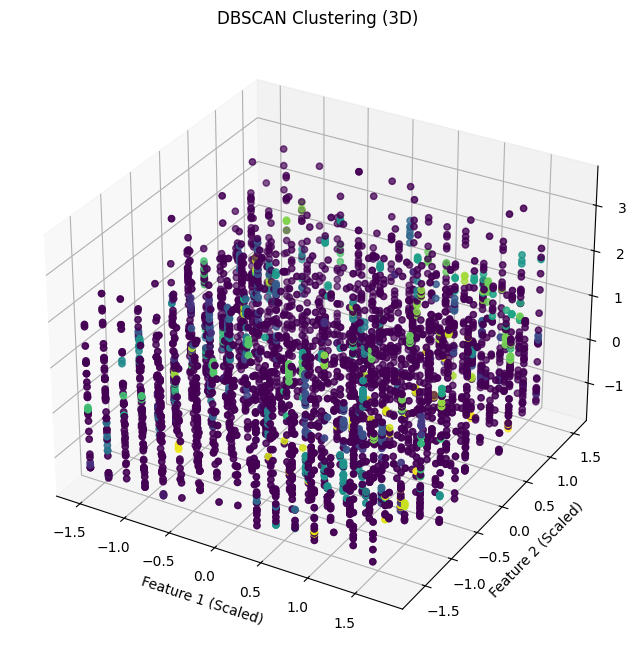

In [ ]:
# visualize the dbscan cluster using 3d


# Visualize the clusters in 3D (assuming you have at least 3 relevant features)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(x_scaled[:, 0], x_scaled[:, 1], x_scaled[:, 2], c=dbscan.labels_, cmap='viridis')  # Replace 0, 1, 2 with your feature indices
ax.set_xlabel('Feature 1 (Scaled)')
ax.set_ylabel('Feature 2 (Scaled)')
ax.set_zlabel('Feature 3 (Scaled)')
ax.set_title('DBSCAN Clustering (3D)')
plt.show()


# Hierarchical Clustering

Hierarchical Cluster Means:
                             Years  SampleDate  Alkalinity-total (as CaCO3)  \
cluster_hierarchical                                                         
0                     2014.437532    5.819423                   200.793409   
1                     2014.463224    5.674491                    65.032196   
2                     2017.000000    4.000000                   130.000000   

                      Ammonia-Total (as N)  BOD - 5 days (Total)     Chloride  \
cluster_hierarchical                                                            
0                                 0.084649              1.599995    22.109336   
1                                 0.116763              1.424707    17.541733   
2                                 0.027000              1.300000  1260.000000   

                      Conductivity @25°C  Dissolved Oxygen  \
cluster_hierarchical                                         
0                             477.698488         6

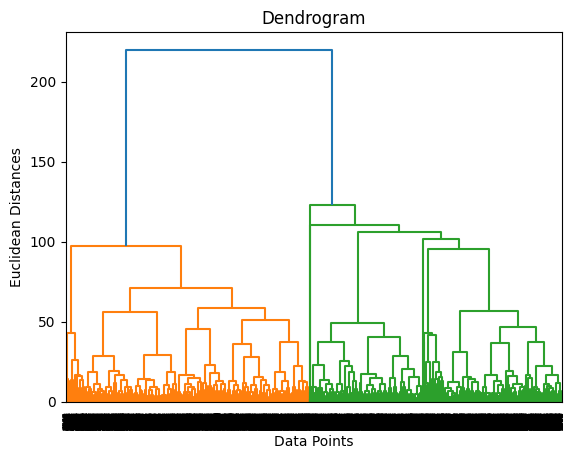

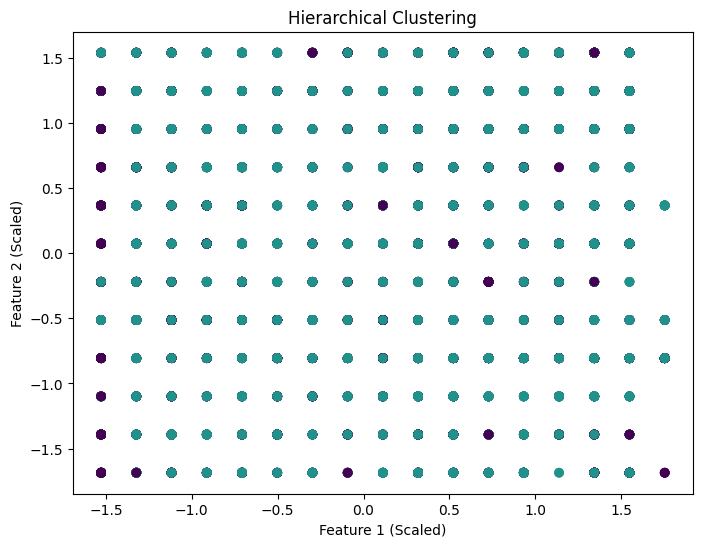

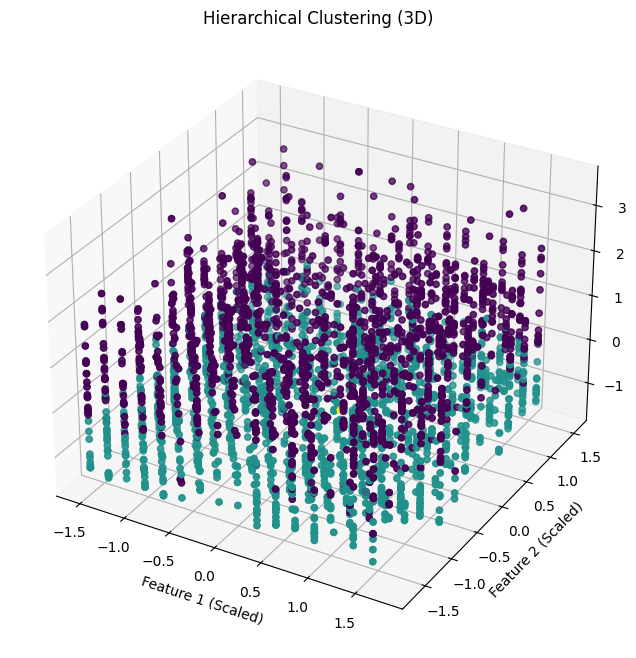

In [ ]:
# compute the hierarchical clsutering for df

from sklearn.cluster import AgglomerativeClustering
import scipy.cluster.hierarchy as sch
import matplotlib.pyplot as plt


# Apply Agglomerative Clustering
# Removed the affinity parameter as it's not needed for 'ward' linkage
agg_clustering = AgglomerativeClustering(n_clusters=3, linkage='ward')  # Adjust n_clusters and linkage as needed
agg_clustering.fit(x_scaled)

# Get the cluster labels for each data point
df['cluster_hierarchical'] = agg_clustering.labels_

# Analyze the clusters
# For example, you can calculate the mean values of features for each cluster
cluster_means_hierarchical = df.groupby('cluster_hierarchical').mean()

# Print the cluster means
print("Hierarchical Cluster Means:\n", cluster_means_hierarchical)

# Evaluate Hierarchical Clustering using silhouette score
silhouette_avg_hierarchical = silhouette_score(x_scaled, agg_clustering.labels_)
print("The average silhouette_score for Hierarchical Clustering is :", silhouette_avg_hierarchical)

# Dendrogram visualization
dendrogram = sch.dendrogram(sch.linkage(x_scaled, method='ward'))  # Adjust method as needed
plt.title('Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Euclidean Distances')
plt.show()

# Visualize the clusters using a scatter plot (assuming you have 2 or 3 relevant features)
plt.figure(figsize=(8, 6))
plt.scatter(x_scaled[:, 0], x_scaled[:, 1], c=agg_clustering.labels_, cmap='viridis')  # Replace 0 and 1 with your feature indices
plt.title('Hierarchical Clustering')
plt.xlabel('Feature 1 (Scaled)')
plt.ylabel('Feature 2 (Scaled)')
plt.show()

# Visualize the clusters in 3D (assuming you have at least 3 relevant features)
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

ax.scatter(x_scaled[:, 0], x_scaled[:, 1], x_scaled[:, 2], c=agg_clustering.labels_, cmap='viridis')  # Replace 0, 1, 2 with your feature indices
ax.set_xlabel('Feature 1 (Scaled)')
ax.set_ylabel('Feature 2 (Scaled)')
ax.set_zlabel('Feature 3 (Scaled)')
ax.set_title('Hierarchical Clustering (3D)')
plt.show()